# Phase 1 | Study design, data, and descriptive statistics

**Research question.** Among participants with normal cognition, how many more or fewer animals are named correctly in 60 seconds per 0.1 mm greater left inferior parietal cortical thickness, after accounting for age, sex, and education?

This phase examines clinical and cognitive data from **UDS** and **MRI** measurements in the **NACC** teaching subset. The unit of analysis is the participant. The initial scientific hypothesis is that greater thickness is associated with a higher score. The association will be estimated in the inference and modeling phases.

[Project card](../PROJECT_CARD.md) · [Course guide](../docs/amarpr.pdf) · [English Phase 1 report](../reports/phase1.pdf)


In [1]:
import os
import subprocess
import sys
from io import BytesIO
from pathlib import Path

from IPython.display import Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "data_audit.py").is_file():
    raise RuntimeError("Open the notebook from the project root or notebooks/ directory.")
os.chdir(root)
sys.path.insert(0, str(root))

from src import phase1_figures as figures
from src.build_dataset import LEFT_THICKNESS, NORMAL_COGNITION, STATUS
from src.data_audit import audit
from src.descriptive_statistics import describe, load_participants

def show_table(headers, rows):
    header = "| " + " | ".join(headers) + " |"
    separator = "| " + " | ".join("---" for _ in headers) + " |"
    body = ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join([header, separator, *body])))

## 1. Data source, participant selection, and file inventory

The two participant-level files come from the teaching subset supplied for the course. UDS includes demographics, medical history, and cognitive tests. The MRI file records cortical thickness and gray matter volume by region. The accompanying matrix is defined at the region level. Thickness is measured in millimeters and volume in cubic millimeters.

Participants were selected at random. The inputs do not specify the sampling frame, collection period, or extract version. Interpretation is limited to the supplied subset and the analysis eligibility rules.

| Variable | Definition and scale | Role |
| --- | --- | --- |
| ANIMALS | Correct responses in 60 seconds, discrete | Primary outcome |
| LH_INFERIORPARIETAL_AVGTH | Left inferior parietal cortical thickness, continuous, in mm | Explanatory variable |
| NACCAGE | Age at the visit, quantitative, in years | Covariate |
| SEX | Recorded sex, nominal | Covariate |
| EDUC | Years of education, discrete | Covariate |
| NACCUDSD | Cognitive status, categorical | Defines the primary sample and comparison groups |


In [2]:
inventory = audit(Path("data"))
matrix = inventory["adjacency_matrix"]
show_table(
    ["File", "Rows", "Columns", "Unit of observation"],
    [
        ("UDS", inventory["uds"]["rows"], inventory["uds"]["columns"], "Participant"),
        ("MRI", inventory["mri"]["rows"], inventory["mri"]["columns"], "Participant"),
        ("Adjacency matrix", matrix["rows"], matrix["data_columns"] + 1, "Brain region"),
    ],
)
group_labels = {
    "identifier": "Identifier",
    "demographics": "Demographics",
    "family_history": "Family history",
    "medications": "Medications",
    "tobacco": "Tobacco",
    "cardiovascular_history": "Cardiovascular history",
    "neurological_history": "Neurological history",
    "other_medical_history": "Other medical history",
    "sleep": "Sleep",
    "psychiatry_and_substance_use": "Psychiatric history and substance use",
    "physical_exam_and_senses": "Physical examination and senses",
    "neurological_exam": "Neurological examination",
    "behavioral_symptoms": "Behavioral symptoms",
    "depression_scale": "Depression scale",
    "everyday_function": "Everyday functioning",
    "subjective_memory_decline": "Subjective memory decline",
    "cognitive_tests": "Cognitive tests",
    "genetics": "Genetics",
    "clinical_diagnosis": "Clinical diagnosis",
    "clinical_dementia_rating": "Clinical Dementia Rating",
}
show_table(
    ["UDS column group", "Columns"],
    [(group_labels.get(name, name), len(columns)) for name, columns in inventory["uds"]["groups"].items()],
)
print("MRI region labels match the matrix:", matrix["matches_mri_region_labels"])

| File | Rows | Columns | Unit of observation |
| --- | --- | --- | --- |
| UDS | 1237 | 180 | Participant |
| MRI | 1237 | 126 | Participant |
| Adjacency matrix | 62 | 63 | Brain region |

| UDS column group | Columns |
| --- | --- |
| Identifier | 1 |
| Demographics | 12 |
| Family history | 11 |
| Medications | 21 |
| Tobacco | 5 |
| Cardiovascular history | 7 |
| Neurological history | 8 |
| Other medical history | 14 |
| Sleep | 4 |
| Psychiatric history and substance use | 11 |
| Physical examination and senses | 12 |
| Neurological examination | 2 |
| Behavioral symptoms | 25 |
| Depression scale | 17 |
| Everyday functioning | 10 |
| Subjective memory decline | 1 |
| Cognitive tests | 9 |
| Genetics | 1 |
| Clinical diagnosis | 1 |
| Clinical Dementia Rating | 8 |

MRI region labels match the matrix: True


## 2. Audit rules

ANIMALS and VEG must be whole-number scores from 0 to 77. Codes 95–98 and −4 are recorded separately from scores. The fractional values of 21.6 for ANIMALS and 16.6 for VEG are retained in the raw columns without rounding and are unavailable for the count analysis. Education code 99 means unknown. The numerical check for thickness requires finite, positive values. Special codes and inconsistent values are reported separately.


In [3]:
fields = [
    ("UDS", "ANIMALS"), ("UDS", "VEG"), ("UDS", "NACCAGE"),
    ("UDS", "SEX"), ("UDS", "EDUC"), ("UDS", STATUS),
    ("MRI", LEFT_THICKNESS), ("MRI", "RH_INFERIORPARIETAL_AVGTH"),
]
audit_rows = []
for source, variable in fields:
    item = inventory[source.lower()]["selected_variables"][variable]
    audit_rows.append((
        source, variable, item["usable"], item["missing_or_special_code"],
        item["unusable"], f"{item['unusable_percent']:.2f}%",
    ))
show_table(
    ["Source", "Variable", "Usable", "Blank or special code", "Total unusable", "Unusable (%)"],
    audit_rows,
)
animal_issues = inventory["uds"]["selected_variables"]["ANIMALS"]["issues"]
show_table(
    ["Reason the ANIMALS score is unavailable", "Count"],
    [
        ("96, cognitive or behavioral problem", animal_issues.get("special_code_96", 0)),
        ("97, other problem", animal_issues.get("special_code_97", 0)),
        ("98, refusal", animal_issues.get("special_code_98", 0)),
        ("Fractional score", animal_issues.get("non_integer", 0)),
    ],
)

| Source | Variable | Usable | Blank or special code | Total unusable | Unusable (%) |
| --- | --- | --- | --- | --- | --- |
| UDS | ANIMALS | 1225 | 11 | 12 | 0.97% |
| UDS | VEG | 1222 | 14 | 15 | 1.21% |
| UDS | NACCAGE | 1237 | 0 | 0 | 0.00% |
| UDS | SEX | 1237 | 0 | 0 | 0.00% |
| UDS | EDUC | 1235 | 2 | 2 | 0.16% |
| UDS | NACCUDSD | 1237 | 0 | 0 | 0.00% |
| MRI | LH_INFERIORPARIETAL_AVGTH | 1237 | 0 | 0 | 0.00% |
| MRI | RH_INFERIORPARIETAL_AVGTH | 1237 | 0 | 0 | 0.00% |

| Reason the ANIMALS score is unavailable | Count |
| --- | --- |
| 96, cognitive or behavioral problem | 2 |
| 97, other problem | 8 |
| 98, refusal | 1 |
| Fractional score | 1 |

## 3. Record linkage and analysis samples

The files join one-to-one on NACCID. Each participant has one supplied record per source. Corresponding visit dates and numbers are unavailable. Cognitive status is compared across the two files, and group labels come from UDS.

The paired sample requires usable score and thickness measurements. The modeling sample also requires usable age, sex, and education. The primary analysis is restricted to normal cognition. Every UDS participant in the supplied files has an MRI record, so the subset has no group of participants without MRI for comparison.


In [4]:
subprocess.run([sys.executable, "-B", "-m", "src.build_dataset"], check=True)
rows, flow = load_participants()
linkage = flow["linkage"]
show_table(
    ["Linkage check", "Participants"],
    [
        ("IDs in UDS", linkage["uds_participants"]),
        ("IDs in MRI", linkage["mri_participants"]),
        ("Matched IDs", linkage["matched_participants"]),
        ("UDS only", linkage["uds_only"]),
        ("MRI only", linkage["mri_only"]),
        ("Agreed on cognitive status", linkage["cognitive_status_agreement"]["equal"]),
    ],
)
sample_labels = {
    "status_and_mri": "Usable cognitive status and thickness",
    "paired_all": "Paired score and thickness, all groups",
    "paired_normal": "Paired score and thickness, normal cognition",
    "model_all": "Supplementary model, all groups",
    "model_normal": "Primary model, normal cognition",
}
show_table(
    ["Analysis sample", "Participants"],
    [
        ("Normal cognition before eligibility filters", flow["matched_normal_cognition_before_eligibility"]),
        *((sample_labels[key], summary["included"]) for key, summary in flow["samples"].items()),
    ],
)

| Linkage check | Participants |
| --- | --- |
| IDs in UDS | 1237 |
| IDs in MRI | 1237 |
| Matched IDs | 1237 |
| UDS only | 0 |
| MRI only | 0 |
| Agreed on cognitive status | 1237 |

| Analysis sample | Participants |
| --- | --- |
| Normal cognition before eligibility filters | 847 |
| Usable cognitive status and thickness | 1237 |
| Paired score and thickness, all groups | 1225 |
| Paired score and thickness, normal cognition | 843 |
| Supplementary model, all groups | 1223 |
| Primary model, normal cognition | 842 |

## 4. Descriptive statistics and group comparisons

Each variable is summarized using its usable values. Quartiles use linear interpolation, and sample standard deviations use the denominator n−1. Values outside the 1.5-IQR fences are counted for review and retained in the summaries.

The mean and standard deviation describe center and spread in the original units and make group comparisons easier. The median describes the center, while the interquartile range covers the middle 50% with less sensitivity to extreme values. The mean and median score are close. Thickness has a tail toward lower values, so the median and interquartile range help describe its central portion.

Group composition and variable-specific denominators differ. The comparisons in this section are descriptive and unadjusted. The group classified as impaired without MCI contains seven participants.


In [5]:
stats = describe(rows, flow)
groups = stats["by_cognitive_status"]
category_labels = {
    "normal cognition": "Normal cognition",
    "impaired without MCI": "Impaired without MCI",
    "MCI": "MCI",
    "dementia": "Dementia",
    "unavailable": "Unavailable",
    "male": "Male",
    "female": "Female",
}
show_table(
    ["Cognitive status", "Group total", "Usable scores", "Mean score", "Usable thickness", "Mean thickness (mm)"],
    [
        (
            category_labels[label], group["participants"],
            group["numeric"]["ANIMALS"]["usable"], f"{group['numeric']['ANIMALS']['mean']:.2f}",
            group["numeric"][LEFT_THICKNESS]["usable"],
            f"{group['numeric'][LEFT_THICKNESS]['mean']:.3f}",
        )
        for label, group in groups.items() if group["participants"]
    ],
)

normal = stats["samples"]["matched_normal"]
numeric_labels = {
    "ANIMALS": "Animal-naming score", LEFT_THICKNESS: "Left thickness (mm)",
    "NACCAGE": "Age (years)", "EDUC": "Education (years)",
}
show_table(
    ["Variable in the normal-cognition group", "Usable", "Mean", "SD", "Minimum", "Q1",
     "Median", "Q3", "Maximum", "IQR"],
    [
        (
            numeric_labels[key], item["usable"],
            *(f"{item[name]:.3f}".rstrip("0").rstrip(".") for name in (
                "mean", "sample_sd", "minimum", "q1", "median", "q3", "maximum", "iqr",
            )),
        )
        for key, item in normal["numeric"].items()
    ],
)
categorical = stats["samples"]["matched_all"]["categorical"]
for column, heading in (("SEX", "Recorded sex"), (STATUS, "Cognitive status")):
    item = categorical[column]
    show_table(
        [heading, "Count", "Percentage of all records", "Percentage of usable records"],
        [
            (category_labels[record["label"]], record["count"],
             f"{record['percent_of_all']:.2f}%", f"{record['percent_of_usable']:.2f}%")
            for record in item["levels"]
        ],
    )

| Cognitive status | Group total | Usable scores | Mean score | Usable thickness | Mean thickness (mm) |
| --- | --- | --- | --- | --- | --- |
| Normal cognition | 847 | 843 | 22.32 | 847 | 2.336 |
| Impaired without MCI | 7 | 7 | 22.00 | 7 | 2.314 |
| MCI | 252 | 249 | 17.83 | 252 | 2.258 |
| Dementia | 131 | 126 | 12.27 | 131 | 2.154 |

| Variable in the normal-cognition group | Usable | Mean | SD | Minimum | Q1 | Median | Q3 | Maximum | IQR |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Animal-naming score | 843 | 22.321 | 5.435 | 7 | 18 | 22 | 26 | 43 | 8 |
| Left thickness (mm) | 847 | 2.336 | 0.121 | 1.474 | 2.269 | 2.338 | 2.417 | 2.666 | 0.148 |
| Age (years) | 847 | 67.272 | 7.916 | 41 | 63 | 67 | 72 | 90 | 9 |
| Education (years) | 846 | 16.382 | 2.613 | 1 | 15 | 16 | 18 | 25 | 3 |

| Recorded sex | Count | Percentage of all records | Percentage of usable records |
| --- | --- | --- | --- |
| Male | 497 | 40.18% | 40.18% |
| Female | 740 | 59.82% | 59.82% |

| Cognitive status | Count | Percentage of all records | Percentage of usable records |
| --- | --- | --- | --- |
| Normal cognition | 847 | 68.47% | 68.47% |
| Impaired without MCI | 7 | 0.57% | 0.57% |
| MCI | 252 | 20.37% | 20.37% |
| Dementia | 131 | 10.59% | 10.59% |

In [6]:
for column in ("ANIMALS", "EDUC"):
    distribution = stats["discrete_frequencies"]["matched_normal"][column]
    display(Markdown(
        f"**{numeric_labels[column]} distribution in the normal-cognition group** "
        f"({distribution['usable']} usable values among {distribution['total']} participants)"
    ))
    show_table(
        ["Value", "Frequency", "Percentage of usable records", "Cumulative percentage"],
        [
            (record["value"], record["count"], f"{record['percent_of_usable']:.2f}%",
             f"{record['cumulative_percent_of_usable']:.2f}%")
            for record in distribution["levels"]
        ],
    )

**Animal-naming score distribution in the normal-cognition group** (843 usable values among 847 participants)

| Value | Frequency | Percentage of usable records | Cumulative percentage |
| --- | --- | --- | --- |
| 7 | 1 | 0.12% | 0.12% |
| 8 | 1 | 0.12% | 0.24% |
| 10 | 4 | 0.47% | 0.71% |
| 11 | 6 | 0.71% | 1.42% |
| 12 | 7 | 0.83% | 2.25% |
| 13 | 16 | 1.90% | 4.15% |
| 14 | 18 | 2.14% | 6.29% |
| 15 | 29 | 3.44% | 9.73% |
| 16 | 29 | 3.44% | 13.17% |
| 17 | 46 | 5.46% | 18.62% |
| 18 | 55 | 6.52% | 25.15% |
| 19 | 50 | 5.93% | 31.08% |
| 20 | 52 | 6.17% | 37.25% |
| 21 | 77 | 9.13% | 46.38% |
| 22 | 71 | 8.42% | 54.80% |
| 23 | 71 | 8.42% | 63.23% |
| 24 | 46 | 5.46% | 68.68% |
| 25 | 38 | 4.51% | 73.19% |
| 26 | 31 | 3.68% | 76.87% |
| 27 | 34 | 4.03% | 80.90% |
| 28 | 47 | 5.58% | 86.48% |
| 29 | 39 | 4.63% | 91.10% |
| 30 | 16 | 1.90% | 93.00% |
| 31 | 20 | 2.37% | 95.37% |
| 32 | 13 | 1.54% | 96.92% |
| 33 | 7 | 0.83% | 97.75% |
| 34 | 2 | 0.24% | 97.98% |
| 35 | 2 | 0.24% | 98.22% |
| 36 | 6 | 0.71% | 98.93% |
| 37 | 4 | 0.47% | 99.41% |
| 38 | 1 | 0.12% | 99.53% |
| 41 | 2 | 0.24% | 99.76% |
| 42 | 1 | 0.12% | 99.88% |
| 43 | 1 | 0.12% | 100.00% |

**Education (years) distribution in the normal-cognition group** (846 usable values among 847 participants)

| Value | Frequency | Percentage of usable records | Cumulative percentage |
| --- | --- | --- | --- |
| 1 | 1 | 0.12% | 0.12% |
| 2 | 1 | 0.12% | 0.24% |
| 6 | 3 | 0.35% | 0.59% |
| 7 | 1 | 0.12% | 0.71% |
| 8 | 2 | 0.24% | 0.95% |
| 9 | 1 | 0.12% | 1.06% |
| 11 | 1 | 0.12% | 1.18% |
| 12 | 70 | 8.27% | 9.46% |
| 13 | 33 | 3.90% | 13.36% |
| 14 | 88 | 10.40% | 23.76% |
| 15 | 19 | 2.25% | 26.00% |
| 16 | 244 | 28.84% | 54.85% |
| 17 | 27 | 3.19% | 58.04% |
| 18 | 226 | 26.71% | 84.75% |
| 19 | 25 | 2.96% | 87.71% |
| 20 | 97 | 11.47% | 99.17% |
| 21 | 2 | 0.24% | 99.41% |
| 22 | 1 | 0.12% | 99.53% |
| 24 | 1 | 0.12% | 99.65% |
| 25 | 3 | 0.35% | 100.00% |

## 5. Figures

The score plot and thickness histogram describe the normal-cognition group. The histogram uses 0.05 mm bins. The cognitive status chart covers all 1,237 matched participants. The box plots show the medians, quartiles, and observations outside the IQR fences. The vector figures linked below are used in the LaTeX report.

[Score](../figures/phase1/01_animal_naming.pdf) · [Thickness](../figures/phase1/02_left_parietal_thickness.pdf) · [Cognitive status](../figures/phase1/03_cognitive_status.pdf) · [Thickness comparison](../figures/phase1/04_thickness_by_status.pdf)


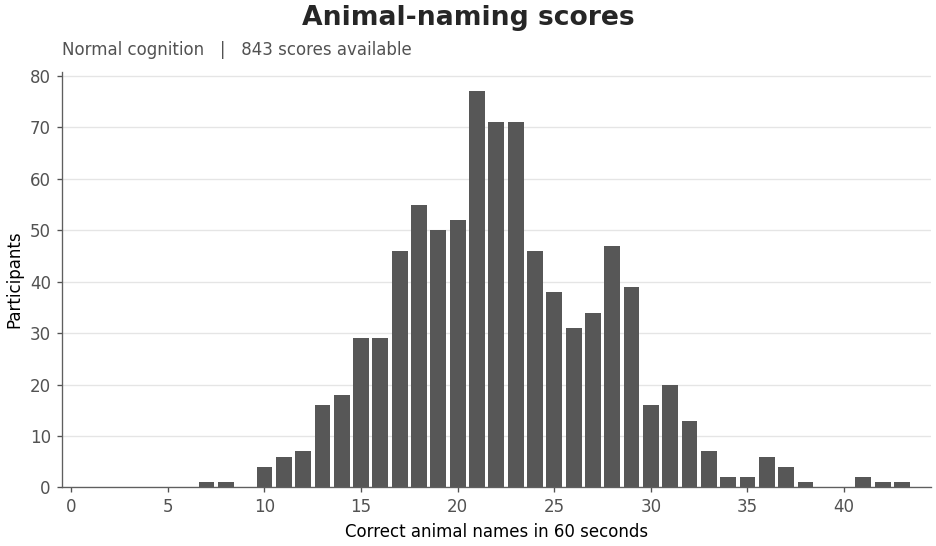

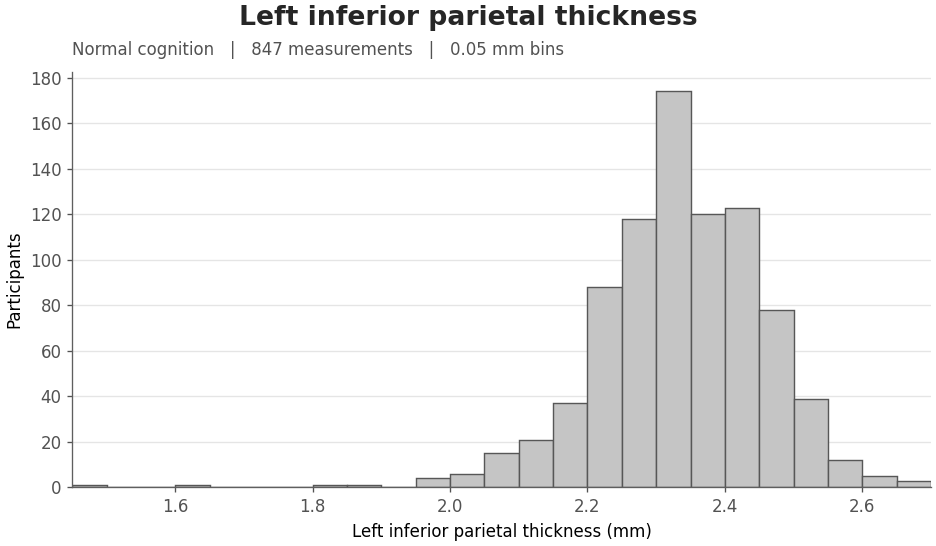

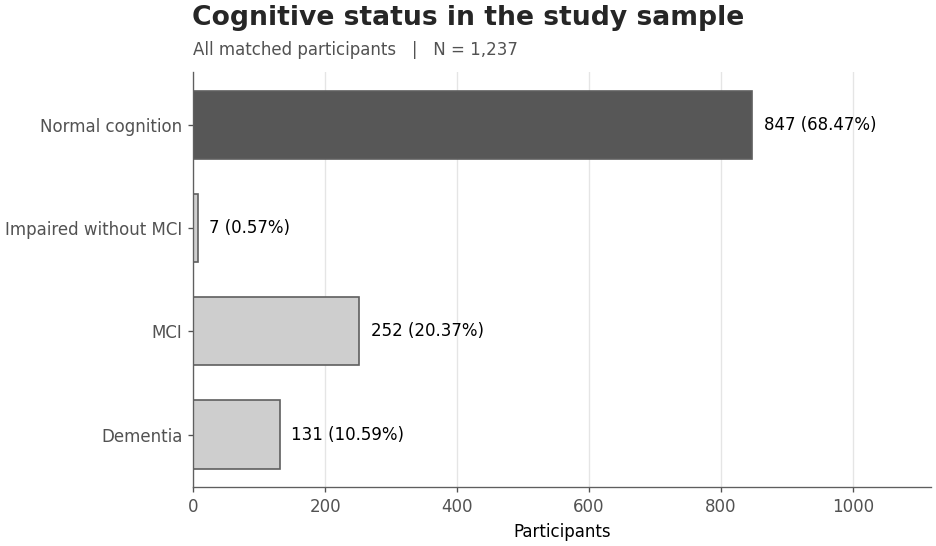

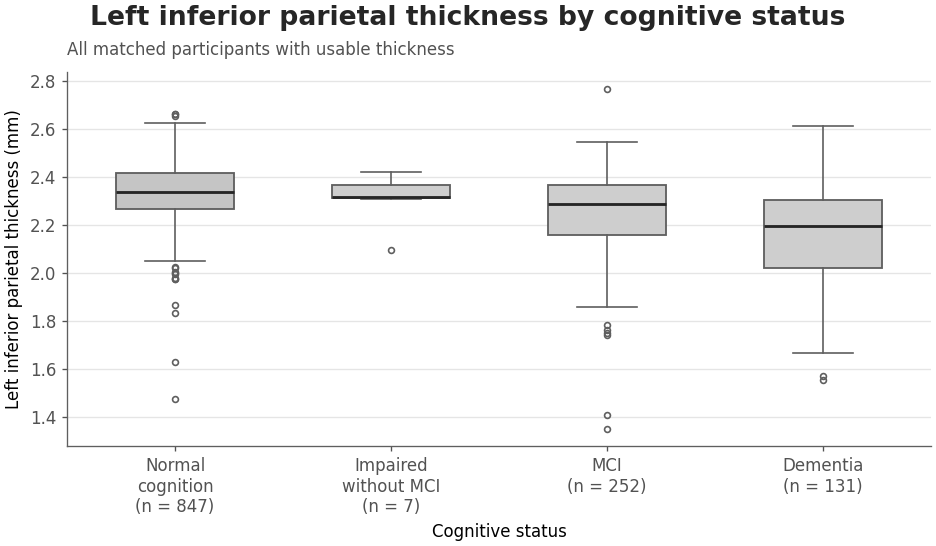

In [7]:
def show_figure(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=120)
        display(Image(data=buffer.getvalue()))
    figures.plt.close(figure)

normal_thickness = [
    row[LEFT_THICKNESS] for row in rows
    if row[STATUS] == NORMAL_COGNITION and row[LEFT_THICKNESS] is not None
]
show_figure(figures.animal_scores(stats["discrete_frequencies"]["matched_normal"]["ANIMALS"]))
show_figure(figures.left_thickness(normal_thickness))
show_figure(figures.cognitive_status(categorical[STATUS]))
show_figure(figures.thickness_by_status(rows, groups))

## 6. Conclusion and limitations

The supplied data support linking score and thickness at the participant level. The adjusted normal-cognition sample contains 842 people. The summaries show the range and spread of both measurements. Answering the question about the within-group association requires estimating the slope and its confidence interval in later phases.

The relative timing of the scan and test, sampling frame, data preparation methods, and imaging quality control are unknown. Results will be interpreted within the observational design and the supplied subset.

[NACC Researcher's Guide](https://www.naccdata.org/the-nacc-researchers-guide/) · [UDS data dictionary](https://r2d2.kumc.edu/ADC/Protocols/UDS2_protocol/ResearchDataDict_2015Mar.pdf#page=205) · [MRI data dictionary](https://files.alz.washington.edu/documentation/SCAN-MRI-Imaging-RDD.pdf#page=17)
